### **Bussines Under Standing**

**Latar Belakang :**

Sebuah perusahaan e-commerce ingin menganalisis perilaku pembeli untuk mengoptimalkan kampanye pemasaran mereka. Mereka memiliki data demografi dan ekonomi pengguna beserta riwayat pembelian. Dengan menggunakan data ini, perusahaan berencana membangun model machine learning untuk memprediksi apakah seorang pengguna akan melakukan pembelian produk tertentu.

**Tujuan :**

Kolom Purchased adalah target dari dataset ini. Perusahaan ingin memprediksi kecenderungan pembelian berdasarkan usia, jenis kelamin, dan estimasi gaji pengguna. Model ini dapat membantu tim pemasaran dalam membuat strategi targeting yang lebih efektif dan personalisasi penawaran.


**Masalah :**

Perusahaan ingin memprediksi apakah seorang pengguna akan melakukan pembelian produk tertentu berdasarkan usia, jenis kelamin, dan estimasi gaji pengguna.

**Solusi :**

Membangun model machine learning Naive Bayes untuk memprediksi kecenderungan pembelian berdasarkan usia, jenis kelamin, dan estimasi gaji pengguna.

**Deskripsi Dataset :**

| Kolom | Deskripsi | Jenis Data |
| --- | --- | --- |
|ID | Nomor identifikasi unik untuk setiap pengguna | Integer (1-1000) |
| Age | Usia pengguna (tahun) | Integer (18-60) |
| Gender | Jenis kelamin pengguna (Male/Female) | Kategorikal |
| EstimatedSalary | Perkiraan gaji tahunan pengguna (dalam satuan mata uang) | Float |
| Purchased | Kolom target yang menunjukkan apakah pengguna melakukan pembelian (1) atau tidak (0) | Integer |


In [224]:
# ============================================================
# FUNGSI : Import seluruh library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, math, tkinter).
# HASIL  : Semua library berhasil dimuat, siap untuk analisis data.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import tkinter as tk

In [225]:
# ============================================================
# FUNGSI : Memuat dataset marketing.csv ke dalam DataFrame.
# HASIL  : Dataset berhasil dimuat: 400 baris x 5 kolom.
# ============================================================
df = pd.read_csv('dataset/marketing.csv')

In [226]:
# ============================================================
# FUNGSI : Menampilkan 5 data awal, ukuran (shape) dan jumlah elemen (size) dataset.
# HASIL  : Shape = (400, 5), Size = 2000 elemen.
# ============================================================
print('5 Data awal :', df.head())
print('-----------------')
print('Shape :', df.shape)
print('-----------------')
print('Size :', df.size)


5 Data awal :       User ID  Gender   Age  EstimatedSalary  Purchased
0  15624510.0    Male  19.0          19000.0        0.0
1  15810944.0    Male  35.0          20000.0        0.0
2  15668575.0  Female  26.0          43000.0        0.0
3  15603246.0  Female  27.0          57000.0        0.0
4  15804002.0    Male  19.0          76000.0        0.0
-----------------
Shape : (400, 5)
-----------------
Size : 2000


In [227]:
# ============================================================
# FUNGSI : Melakukan encoding kolom Gender menjadi numerik (Male=1, Female=0).
# HASIL  : Gender berhasil diubah ke angka agar bisa diproses model.
# ============================================================
df['Gender'] = df['Gender'].map({'Male' : 1, 'Female' : 0})

In [228]:
# ============================================================
# FUNGSI : Menampilkan 8 baris pertama data setelah encoding Gender.
# HASIL  : Kolom Gender sudah bernilai 0/1.
# ============================================================
df.head(8)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510.0,1,19.0,19000.0,0.0
1,15810944.0,1,35.0,20000.0,0.0
2,15668575.0,0,26.0,43000.0,0.0
3,15603246.0,0,27.0,57000.0,0.0
4,15804002.0,1,19.0,76000.0,0.0
5,15728773.0,1,27.0,58000.0,0.0
6,15598044.0,0,27.0,84000.0,0.0
7,15694829.0,0,32.0,150000.0,1.0


### **EDA**



In [229]:
# ============================================================
# FUNGSI : Mengecek tipe data setiap kolom.
# HASIL  : Gender bertipe object, kolom lainnya bertipe float64.
# ============================================================
df.dtypes

User ID            float64
Gender               int64
Age                float64
EstimatedSalary    float64
Purchased          float64
dtype: object

In [230]:
# ============================================================
# FUNGSI : Statistik deskriptif kolom numerik (mean, std, min, max, kuartil).
# HASIL  : Age rata-rata 37.66 (18-60), EstimatedSalary rata-rata 69.742 (15.000-150.000), Purchased rata-rata 0.36.
# ============================================================
df.describe()

,User ID,Gender,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000,400.000000
mean,1.569154e+07,0.490000,37.655000,69742.500000,0.357500
std,7.165832e+04,0.500526,10.482877,34096.960282,0.479864
min,1.556669e+07,0.000000,18.000000,15000.000000,0.000000
25%,1.562676e+07,0.000000,29.750000,43000.000000,0.000000
50%,1.569434e+07,0.000000,37.000000,70000.000000,0.000000
75%,1.575036e+07,1.000000,46.000000,88000.000000,1.000000
max,1.581524e+07,1.000000,60.000000,150000.000000,1.000000


In [231]:
# ============================================================
# FUNGSI : Menampilkan ringkasan info dataset (tipe data & jumlah non-null).
# HASIL  : 400 entri, 5 kolom, tidak ada nilai null.
# ============================================================
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   User ID          400 non-null    float64
 1   Gender           400 non-null    int64  
 2   Age              400 non-null    float64
 3   EstimatedSalary  400 non-null    float64
 4   Purchased        400 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 15.8 KB


In [232]:
# ============================================================
# FUNGSI : Mengecek jumlah baris duplikat.
# HASIL  : 0 duplikat, data unik.
# ============================================================
df.duplicated().sum()

np.int64(0)

In [233]:
# ============================================================
# FUNGSI : Mengecek jumlah nilai kosong (missing value) tiap kolom.
# HASIL  : Tidak ada nilai null (total null = 0).
# ============================================================
print(df.isnull().sum())
print('Total Nilai Null:', df.isnull().sum().sum())


User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Total Nilai Null: 0


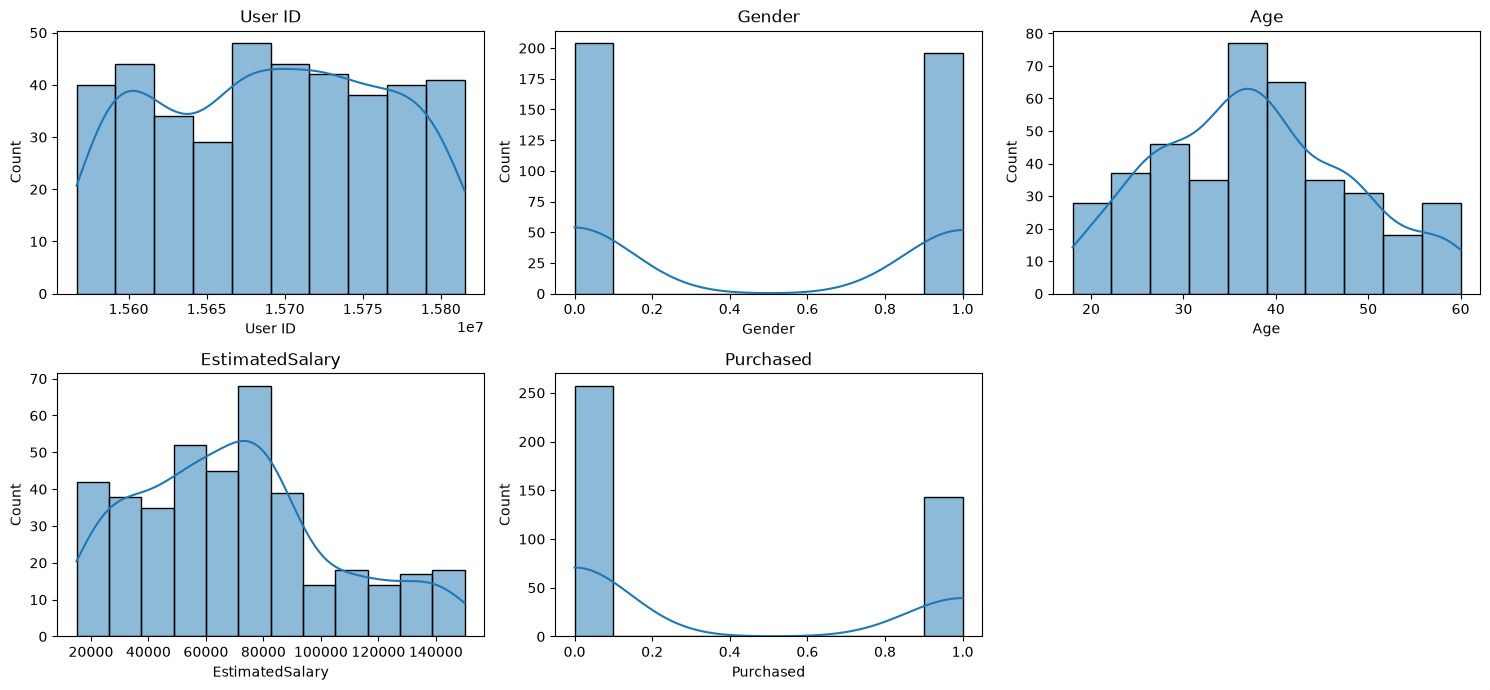

In [234]:
# ============================================================
# FUNGSI : Visualisasi histogram + KDE untuk melihat distribusi tiap fitur numerik.
# HASIL  : Distribusi fitur numerik tampak wajar tanpa keanehan mencolok.
# ============================================================
kolom = df.select_dtypes(include='number').columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(kolom):
    plt.subplot(3, 3, i+1)
    sns.histplot(df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

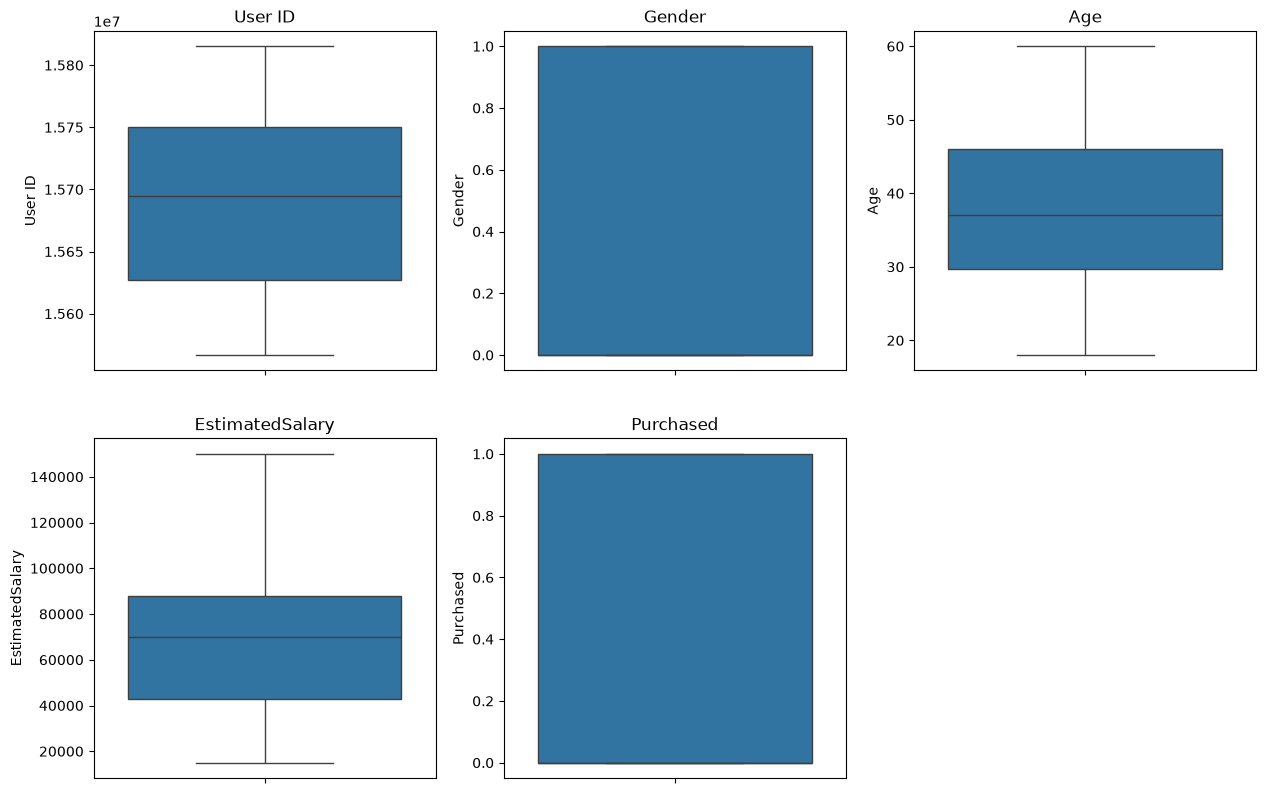

In [235]:
# ============================================================
# FUNGSI : Visualisasi boxplot untuk melihat sebaran dan keberadaan outlier.
# HASIL  : Sebaran data relatif normal, tidak terlihat outlier ekstrem.
# ============================================================
plt.figure(figsize=(15,15))

for i, col in enumerate(kolom):
    plt.subplot(3, 3, i+1)
    sns.boxplot(df[col])
    plt.title(col)

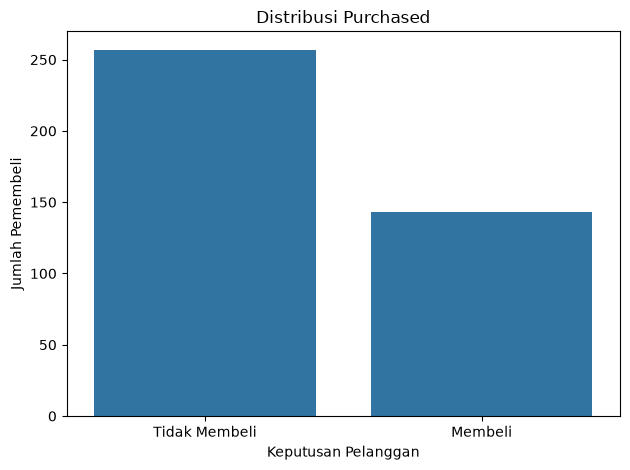

In [236]:
# ============================================================
# FUNGSI : Visualisasi distribusi target Purchased (jumlah membeli vs tidak).
# HASIL  : 257 tidak membeli (64.25%) vs 143 membeli (35.75%) -> imbalance ringan.
# ============================================================
sns.countplot(data=df, x='Purchased')
plt.title('Distribusi Purchased')
plt.xticks([0, 1], ['Tidak Membeli', 'Membeli'])
plt.ylabel('Jumlah Pemembeli')
plt.xlabel('Keputusan Pelanggan')
plt.tight_layout()
plt.show()


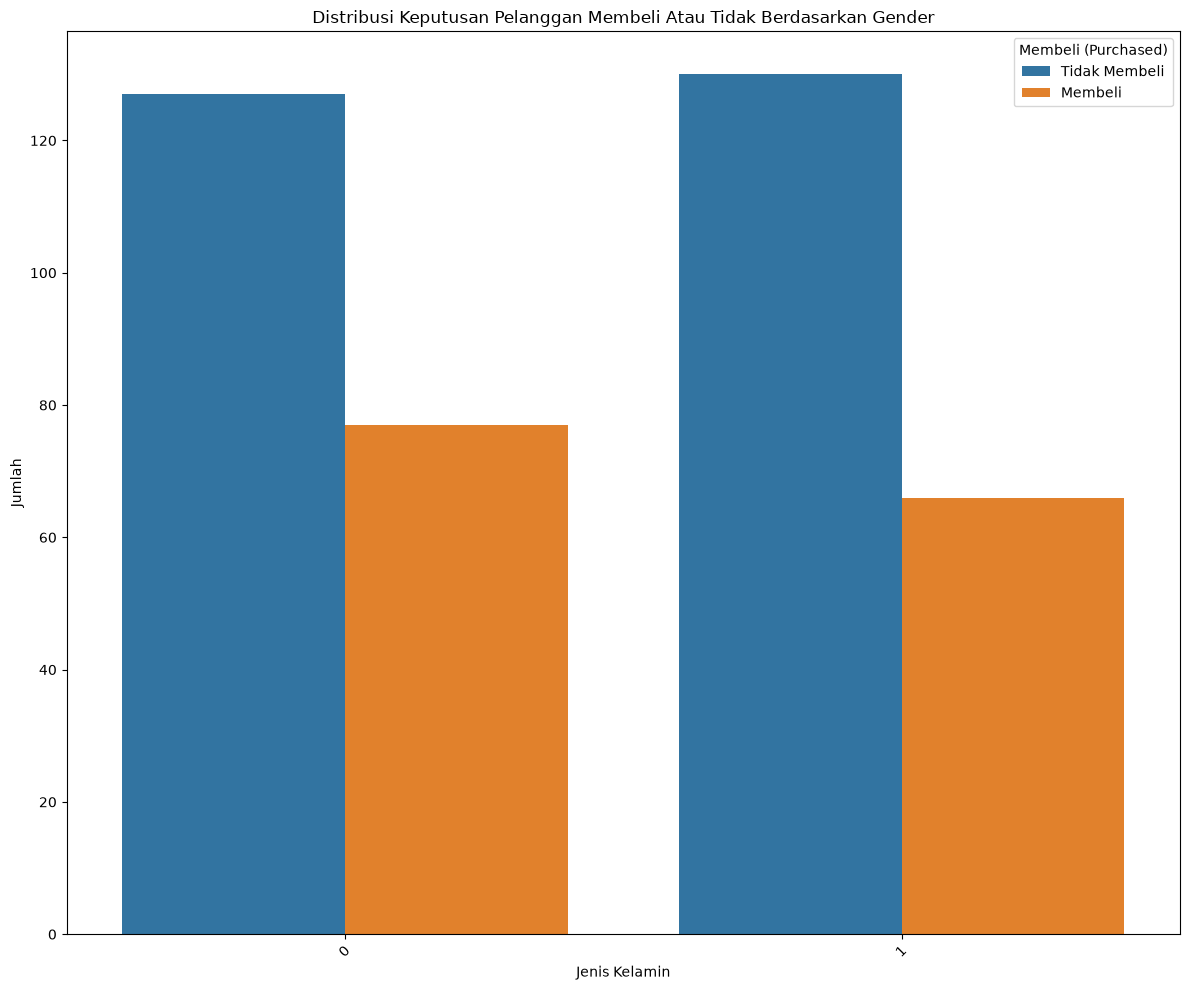

In [237]:
# ============================================================
# FUNGSI : Visualisasi keputusan pembelian berdasarkan Gender.
# HASIL  : Female 77 membeli dari 204, Male 66 membeli dari 196 -> selisih kecil, Gender bukan pembeda kuat.
# ============================================================
plt.figure(figsize=(12, 10))
sns.countplot(data=df, x='Gender', hue='Purchased')
plt.title('Distribusi Keputusan Pelanggan Membeli Atau Tidak Berdasarkan Gender')
plt.xlabel('Jenis Kelamin')
plt.ylabel('Jumlah')
plt.xticks(rotation=45)
plt.legend(title='Membeli (Purchased)', loc='upper right', labels=['Tidak Membeli', 'Membeli'])
plt.tight_layout()
plt.show()

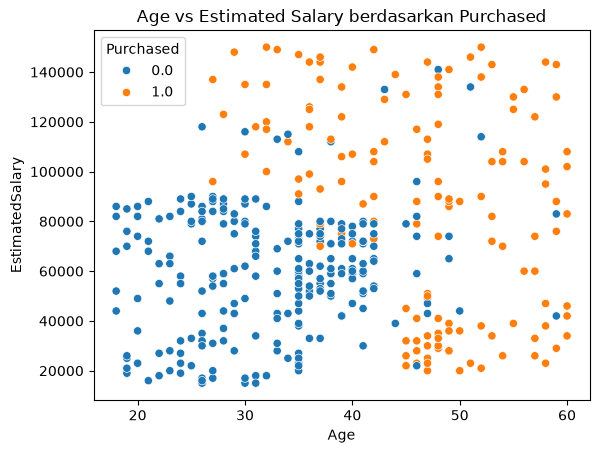

In [238]:
# ============================================================
# FUNGSI : Scatterplot Age vs EstimatedSalary diwarnai berdasarkan Purchased.
# HASIL  : Kelas pembeli cenderung berkumpul di usia dan gaji lebih tinggi.
# ============================================================
sns.scatterplot(
    data=df,
    x='Age',
    y='EstimatedSalary',
    hue='Purchased'
)

plt.title('Age vs Estimated Salary berdasarkan Purchased')
plt.show()

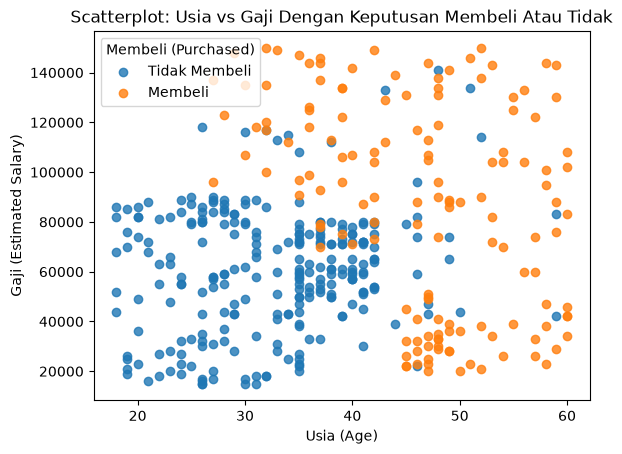

In [239]:
# ============================================================
# FUNGSI : Scatterplot dipisah per kelas (membeli vs tidak membeli).
# HASIL  : Terlihat pemisahan antarkelas yang cukup jelas -> potensi akurasi tinggi.
# ============================================================
tidak_membeli = df[df['Purchased'] == 0]
membeli = df[df['Purchased'] == 1]

plt.scatter(
    tidak_membeli['Age'],
    tidak_membeli['EstimatedSalary'],
    alpha=0.8,
    label='Tidak Membeli'
)

plt.scatter(
    membeli['Age'],
    membeli['EstimatedSalary'],
    alpha=0.8,
    label='Membeli'
)

plt.title('Scatterplot: Usia vs Gaji Dengan Keputusan Membeli Atau Tidak')
plt.xlabel('Usia (Age)')
plt.ylabel('Gaji (Estimated Salary)')
plt.legend(title='Membeli (Purchased)', loc='upper left',labels=['Tidak Membeli', 'Membeli'])
plt.show()

In [240]:
# ============================================================
# FUNGSI : Deteksi outlier dengan metode IQR (Q1, Q3, batas bawah & atas).
# HASIL  : 0 outlier pada semua kolom, tidak perlu pembersihan data.
# ============================================================
cols = ['Age', 'EstimatedSalary', 'Purchased', 'Gender', 'User ID']

Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)

IQR =  Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df[cols] < batas_bawah) | (df[cols] > batas_atas)).sum()
print("Jumlah outlier per kolom:")
print(outlier)

Jumlah outlier per kolom:
Age                0
EstimatedSalary    0
Purchased          0
Gender             0
User ID            0
dtype: int64


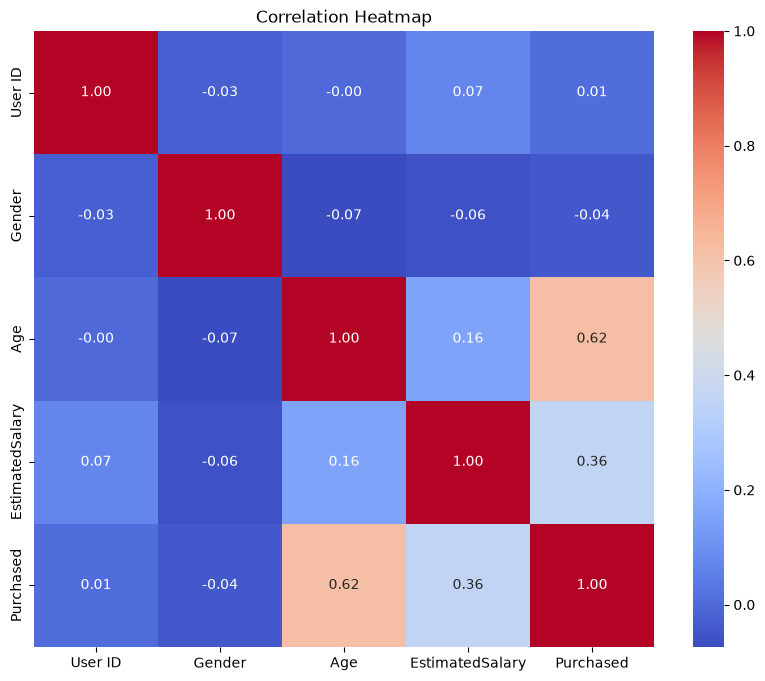

In [241]:
# ============================================================
# FUNGSI : Heatmap korelasi antar fitur numerik.
# HASIL  : Korelasi tertinggi: Age-Purchased 0.62 dan EstimatedSalary-Purchased 0.36; User ID & Gender hampir 0.
# ============================================================
plt.figure(figsize=(10, 8))
sns.heatmap(
    df.select_dtypes(include=['int64', 'float64']).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [242]:
# ============================================================
# FUNGSI : Menghapus kolom User ID karena tidak punya daya prediksi.
# HASIL  : Kolom User ID dibuang dari dataset.
# ============================================================
df = df.drop(columns=['User ID'])


In [243]:
# ============================================================
# FUNGSI : Memisahkan fitur (X) dan target (y).
# HASIL  : X = Gender, Age, EstimatedSalary ; y = Purchased.
# ============================================================
X = df.drop(columns=['Purchased'])
y = df['Purchased']


# Modeling Naive Bayes (Gaussian) Tanpa Sklearn
Tahapan: **menghitung Prior -> Likelihood -> Posterior**, lalu dievaluasi dengan Accuracy, Precision, Recall, F1-Score, dan Confusion Matrix.

## 0. Split Data Train & Test (Manual, Tanpa Sklearn)

In [244]:
# ============================================================
# FUNGSI : Split data manual 80% train - 20% test (tanpa sklearn) dengan seed 42.
# HASIL  : 320 data train dan 80 data test.
# ============================================================
# Split data manual 80% train - 20% test
np.random.seed(42)
indeks = np.random.permutation(len(df))
n_test = int(0.2 * len(df))

indeks_test = indeks[:n_test]
indeks_train = indeks[n_test:]

X_train = X.iloc[indeks_train].reset_index(drop=True)
X_test  = X.iloc[indeks_test].reset_index(drop=True)
y_train = y.iloc[indeks_train].reset_index(drop=True)
y_test  = y.iloc[indeks_test].reset_index(drop=True)

print('Jumlah data train :', len(X_train))
print('Jumlah data test  :', len(X_test))
print('Fitur             :', X_train.columns.tolist())

Jumlah data train : 320
Jumlah data test  : 80
Fitur             : ['Gender', 'Age', 'EstimatedSalary']


## 1. Menghitung Prior  $P(y)$
Prior = proporsi tiap kelas pada data training.

In [245]:
# ============================================================
# FUNGSI : Menghitung Prior P(y) = proporsi tiap kelas pada data train.
# HASIL  : P(Tidak Membeli)=0.6406, P(Membeli)=0.3594.
# ============================================================
# 1. MENGHITUNG PRIOR P(y)
kelas = sorted(y_train.unique())
n_total = len(y_train)

prior = {}
for k in kelas:
    prior[k] = (y_train == k).sum() / n_total

print('=== PRIOR P(y) ===')
for k in kelas:
    label = 'Membeli' if k == 1 else 'Tidak Membeli'
    print(f'P(Purchased={k}) [{label}] = {prior[k]:.4f}')

=== PRIOR P(y) ===
P(Purchased=0.0) [Tidak Membeli] = 0.6406
P(Purchased=1.0) [Membeli] = 0.3594


## 2. Menghitung Likelihood  $P(x_i \mid y)$
Karena fitur kontinu, dipakai **distribusi Gaussian**:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x_i-\mu)^2}{2\sigma^2}\right)$$

In [246]:
# ============================================================
# FUNGSI : Menghitung Likelihood berupa mean & std tiap fitur per kelas (distribusi Gaussian).
# HASIL  : Age kelas 0 mean 33.4 / kelas 1 mean 45.83; Salary kelas 0 mean 60.498 / kelas 1 mean 87.722 -> antar kelas terpisah jelas.
# ============================================================
# 2. MENGHITUNG LIKELIHOOD -> parameter mean & std tiap fitur per kelas
fitur = X_train.columns.tolist()

mean = {}
std = {}

for k in kelas:
    mean[k] = {}
    std[k] = {}
    for f in fitur:
        data_kelas = X_train.loc[y_train == k, f]
        mean[k][f] = data_kelas.mean()
        std[k][f]  = data_kelas.std()

print('=== PARAMETER LIKELIHOOD (Mean & Std) ===')
for k in kelas:
    print(f'\nKelas Purchased = {k}')
    for f in fitur:
        print(f'  {f:16s} -> mean = {mean[k][f]:12.4f} | std = {std[k][f]:12.4f}')

=== PARAMETER LIKELIHOOD (Mean & Std) ===

Kelas Purchased = 0.0
  Gender           -> mean =       0.5122 | std =       0.5011
  Age              -> mean =      33.4049 | std =       7.9918
  EstimatedSalary  -> mean =   60497.5610 | std =   24634.9076

Kelas Purchased = 1.0
  Gender           -> mean =       0.4783 | std =       0.5017
  Age              -> mean =      45.8348 | std =       8.7989
  EstimatedSalary  -> mean =   87721.7391 | std =   41859.9477


## 2b. Visualisasi Kurva Gaussian (Likelihood)
Kurva densitas Gaussian yang di-fit untuk tiap fitur pada masing-masing kelas. Semakin jarak antar kurva kedua kelas, semakin kuat fitur tersebut memisahkan kelas.

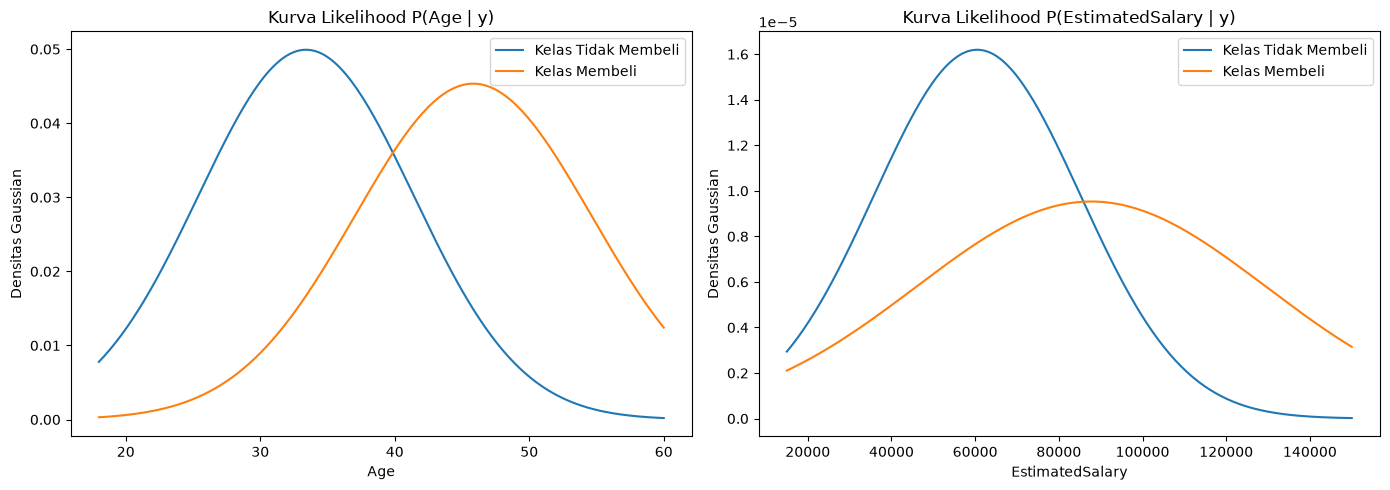

In [247]:
# ============================================================
# FUNGSI : Menampilkan kurva Gaussian (likelihood) tiap fitur per kelas.
# HASIL  : Kurva Age & EstimatedSalary antar kelas terpisah jelas -> fitur
#          tersebut informatif untuk memisahkan kelas.
# ============================================================
fitur_viz = ['Age', 'EstimatedSalary']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, f in zip(axes, fitur_viz):
    x_axis = np.linspace(X_train[f].min(), X_train[f].max(), 200)
    for k in kelas:
        y_axis = [gaussian(x, mean[k][f], std[k][f]) for x in x_axis]
        label = 'Membeli' if k == 1 else 'Tidak Membeli'
        ax.plot(x_axis, y_axis, label=f'Kelas {label}')
    ax.set_title(f'Kurva Likelihood P({f} | y)')
    ax.set_xlabel(f)
    ax.set_ylabel('Densitas Gaussian')
    ax.legend()

plt.tight_layout()
plt.show()

## 3. Menghitung Posterior  $P(y \mid x) \propto P(y) \prod P(x_i \mid y)$
Posterior = prior dikali seluruh likelihood fitur, lalu kelas dengan nilai posterior terbesar dipilih sebagai hasil prediksi.

In [248]:
# ============================================================
# FUNGSI : Membuat fungsi Gaussian, menghitung Posterior P(y)*prod P(x|y), dan fungsi prediksi; ditampilkan contoh 1 baris.
# HASIL  : Kelas dengan nilai posterior terbesar dipilih sebagai hasil prediksi.
# ============================================================
# Fungsi probabilitas densitas Gaussian
def gaussian(x, mu, sigma):
    if sigma == 0:
        sigma = 1e-9
    return (1 / (math.sqrt(2 * math.pi) * sigma)) * math.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

# 3. MENGHITUNG POSTERIOR P(y|x) ~ P(y) * prod P(x_i|y)
def hitung_posterior(baris):
    posterior = {}
    for k in kelas:
        prob = prior[k]                    # mulai dari prior
        for f in fitur:
            prob *= gaussian(baris[f], mean[k][f], std[k][f])  # kalikan likelihood
        posterior[k] = prob
    return posterior

def prediksi_kelas(baris):
    posterior = hitung_posterior(baris)
    return max(posterior, key=posterior.get)

# Contoh perhitungan posterior untuk 1 baris data test
contoh = X_test.iloc[0]
print('=== CONTOH POSTERIOR (baris ke-0 data test) ===')
print('Nilai fitur :', contoh.to_dict())
pos = hitung_posterior(contoh)
for k in kelas:
    label = 'Membeli' if k == 1 else 'Tidak Membeli'
    print(f'  Posterior P({label}|x) = {pos[k]:.10f}')
print('Prediksi   :', prediksi_kelas(contoh), '| Aktual :', y_test.iloc[0])

=== CONTOH POSTERIOR (baris ke-0 data test) ===
Nilai fitur : {'Gender': 0.0, 'Age': 46.0, 'EstimatedSalary': 22000.0}
  Posterior P(Tidak Membeli|x) = 0.0000000208
  Posterior P(Membeli|x) = 0.0000000229
Prediksi   : 1.0 | Aktual : 0.0


## 4. Prediksi Seluruh Data Test

In [249]:
# ============================================================
# FUNGSI : Memprediksi seluruh data test dan menampilkan tabel Aktual vs Prediksi.
# HASIL  : Prediksi berhasil untuk 80 data test.
# ============================================================
y_pred = X_test.apply(prediksi_kelas, axis=1)

hasil = X_test.copy()
hasil['Aktual'] = y_test.values
hasil['Prediksi'] = y_pred.values
hasil.head(10)

,Gender,Age,EstimatedSalary,Aktual,Prediksi
0,0,46.0,22000.0,0.0,1.0
1,0,59.0,88000.0,1.0,1.0
2,0,28.0,44000.0,0.0,0.0
3,0,48.0,96000.0,1.0,1.0
4,0,29.0,28000.0,0.0,0.0
5,0,30.0,62000.0,0.0,0.0
6,0,47.0,107000.0,1.0,1.0
7,0,29.0,83000.0,0.0,0.0
8,1,40.0,75000.0,0.0,0.0
9,1,42.0,65000.0,0.0,0.0


## 4b. Visualisasi Decision Boundary Naive Bayes
Area keputusan model pada bidang **Age vs EstimatedSalary**. Warna menunjukkan kelas hasil prediksi, titik menunjukkan data aktual.

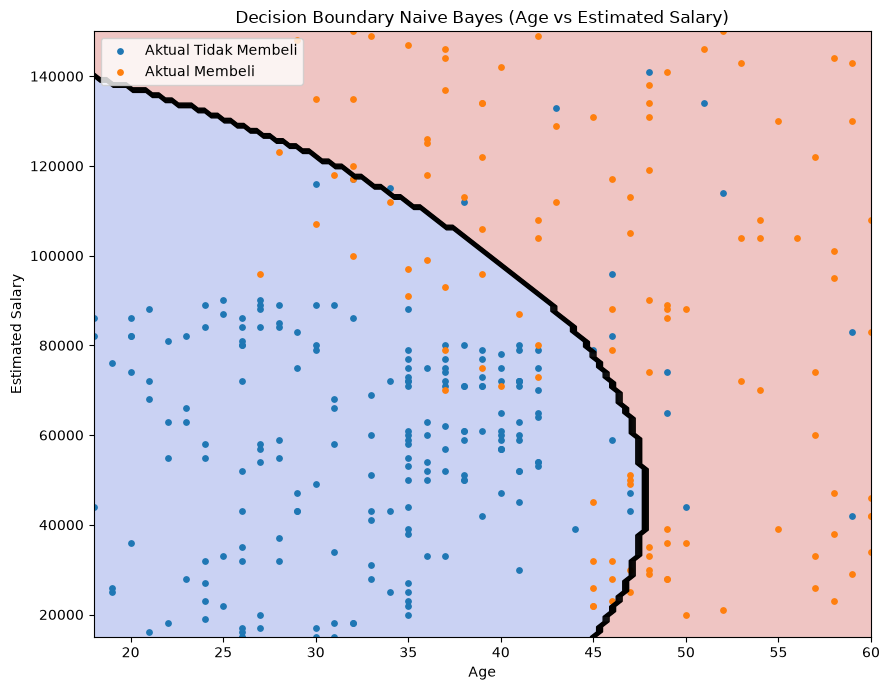

In [250]:
# ============================================================
# FUNGSI : Menggambar decision boundary model pada bidang Age vs EstimatedSalary.
# HASIL  : Garis keputusan membelah berdasarkan umur & gaji (miring ke arah keduanya),
#          membuktikan prediksi bergantung pada kedua fitur numerik tersebut.
# ============================================================
age_axis = np.linspace(X_train['Age'].min(), X_train['Age'].max(), 120)
sal_axis = np.linspace(X_train['EstimatedSalary'].min(), X_train['EstimatedSalary'].max(), 120)
AA, SS = np.meshgrid(age_axis, sal_axis)

# Prediksi tiap titik grid (Gender dinetralkan = 1)
Z = np.zeros(AA.shape)
for i in range(AA.shape[0]):
    for j in range(AA.shape[1]):
        Z[i, j] = prediksi_kelas({'Gender': 1, 'Age': AA[i, j], 'EstimatedSalary': SS[i, j]})

plt.figure(figsize=(9, 7))
plt.contourf(AA, SS, Z, alpha=0.3, cmap='coolwarm')
plt.contour(AA, SS, Z, colors='k', linewidths=1)
for k in kelas:
    d = X_train[y_train == k]
    label = 'Membeli' if k == 1 else 'Tidak Membeli'
    plt.scatter(d['Age'], d['EstimatedSalary'], s=15, label=f'Aktual {label}')
plt.title('Decision Boundary Naive Bayes (Age vs Estimated Salary)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Evaluasi Model
- **Confusion Matrix**: TP, TN, FP, FN
- **Accuracy** = (TP+TN) / Total
- **Precision** = TP / (TP+FP)
- **Recall** = TP / (TP+FN)
- **F1-Score** = 2 * (Precision * Recall) / (Precision + Recall)

In [251]:
# ============================================================
# FUNGSI : Menghitung Confusion Matrix (TP, TN, FP, FN) dan metrik Accuracy, Precision, Recall, F1-Score.
# HASIL  : TP=25, TN=50, FP=2, FN=3 | Accuracy 93.75%, Precision 92.59%, Recall 89.29%, F1-Score 90.91%.
# ============================================================
# 5. MENGHITUNG CONFUSION MATRIX (manual)
TP = ((y_test == 1) & (y_pred == 1)).sum()
TN = ((y_test == 0) & (y_pred == 0)).sum()
FP = ((y_test == 0) & (y_pred == 1)).sum()
FN = ((y_test == 1) & (y_pred == 0)).sum()

cm = np.array([[TN, FP], [FN, TP]])
df_cm = pd.DataFrame(cm,
                     index=['Aktual: Tidak Membeli', 'Aktual: Membeli'],
                     columns=['Prediksi: Tidak Membeli', 'Prediksi: Membeli'])
print('=== CONFUSION MATRIX ===')
print(df_cm)

# Metrik evaluasi
accuracy  = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score  = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print('\n=== HASIL EVALUASI ===')
print(f'TP = {TP} | TN = {TN} | FP = {FP} | FN = {FN}')
print(f'Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Precision : {precision:.4f} ({precision*100:.2f}%)')
print(f'Recall    : {recall:.4f} ({recall*100:.2f}%)')
print(f'F1-Score  : {f1_score:.4f} ({f1_score*100:.2f}%)')

=== CONFUSION MATRIX ===
                       Prediksi: Tidak Membeli  Prediksi: Membeli
Aktual: Tidak Membeli                       50                  2
Aktual: Membeli                              3                 25

=== HASIL EVALUASI ===
TP = 25 | TN = 50 | FP = 2 | FN = 3
Accuracy  : 0.9375 (93.75%)
Precision : 0.9259 (92.59%)
Recall    : 0.8929 (89.29%)
F1-Score  : 0.9091 (90.91%)


## 6. Visualisasi Confusion Matrix

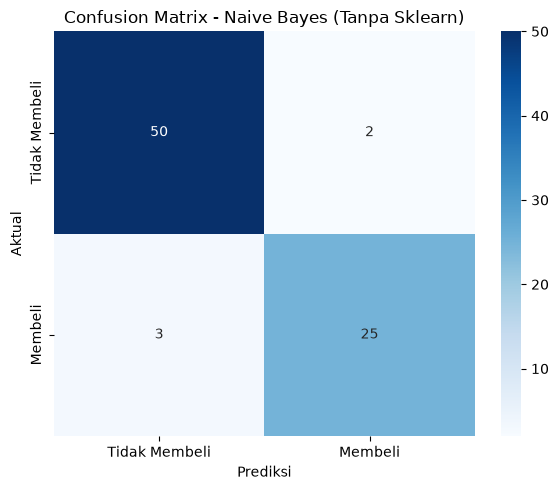

In [252]:
# ============================================================
# FUNGSI : Visualisasi Confusion Matrix dalam bentuk heatmap.
# HASIL  : Heatmap menunjukkan 50 TN & 25 TP sebagai tebakan benar terbanyak.
# ============================================================
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Membeli', 'Membeli'],
            yticklabels=['Tidak Membeli', 'Membeli'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Naive Bayes (Tanpa Sklearn)')
plt.tight_layout()
plt.show()

## 6b. Confusion Matrix Ternormalisasi (%)
Setiap baris dinormalisasi terhadap total aktualnya, sehingga terbaca berapa persen data tiap kelas yang diprediksi benar.

=== CONFUSION MATRIX TERNORMALISASI (%) ===
                       Prediksi: Tidak Membeli  Prediksi: Membeli
Aktual: Tidak Membeli                    96.15               3.85
Aktual: Membeli                          10.71              89.29


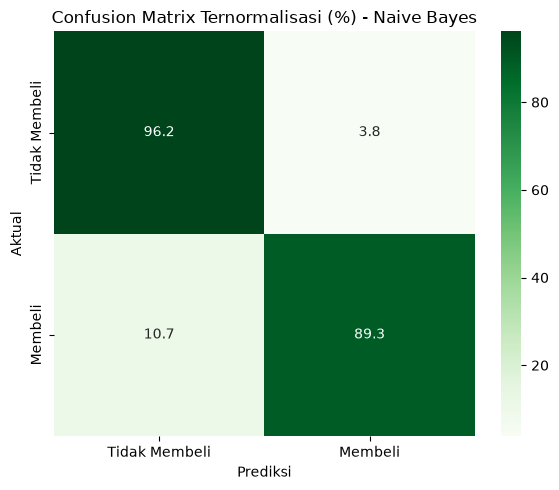

In [253]:
# ============================================================
# FUNGSI : Menampilkan confusion matrix ternormalisasi (persen per baris/aktual).
# HASIL  : Baris 'Tidak Membeli' = 96.15% benar, baris 'Membeli' = 89.29% benar.
# ============================================================
cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100

df_cm_norm = pd.DataFrame(cm_norm.round(2),
                          index=['Aktual: Tidak Membeli', 'Aktual: Membeli'],
                          columns=['Prediksi: Tidak Membeli', 'Prediksi: Membeli'])
print('=== CONFUSION MATRIX TERNORMALISASI (%) ===')
print(df_cm_norm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Greens',
            xticklabels=['Tidak Membeli', 'Membeli'],
            yticklabels=['Tidak Membeli', 'Membeli'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix Ternormalisasi (%) - Naive Bayes')
plt.tight_layout()
plt.show()

## 7. Ringkasan Metrik Evaluasi

In [254]:
# ============================================================
# FUNGSI : Membuat tabel ringkasan seluruh metrik evaluasi.
# HASIL  : Ringkasan: Accuracy 93.75%, Precision 92.59%, Recall 89.29%, F1-Score 90.91%.
# ============================================================
metrik = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai': [accuracy, precision, recall, f1_score],
    'Persen (%)': [accuracy*100, precision*100, recall*100, f1_score*100]
}).round(4)

metrik

,Metrik,Nilai,Persen (%)
0,Accuracy,0.9375,93.7500
1,Precision,0.9259,92.5926
2,Recall,0.8929,89.2857
3,F1-Score,0.9091,90.9091


## 8. Bar Chart Metrik Evaluasi

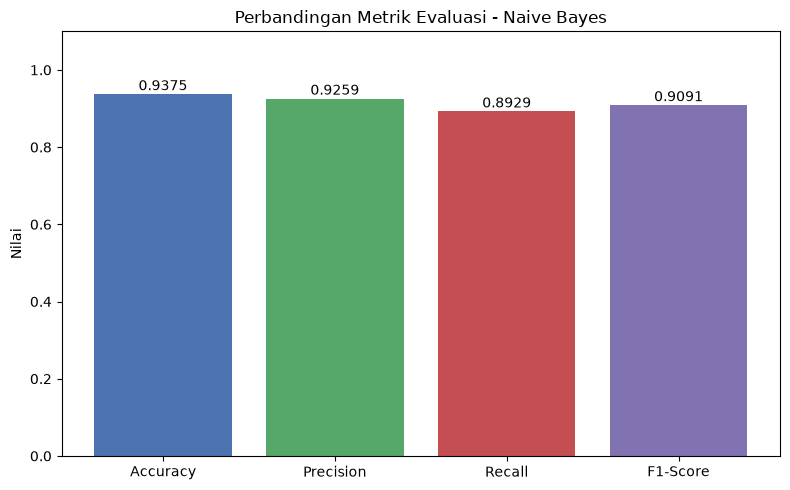

In [255]:
# ============================================================
# FUNGSI : Menampilkan perbandingan metrik evaluasi dalam diagram batang.
# HASIL  : Accuracy 93.75%, Precision 92.59%, Recall 89.29%, F1-Score 90.91%.
# ============================================================
nama_metrik = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
nilai_metrik = [accuracy, precision, recall, f1_score]

plt.figure(figsize=(8, 5))
bars = plt.bar(nama_metrik, nilai_metrik, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
for bar, v in zip(bars, nilai_metrik):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.4f}', ha='center')
plt.ylim(0, 1.1)
plt.title('Perbandingan Metrik Evaluasi - Naive Bayes')
plt.ylabel('Nilai')
plt.tight_layout()
plt.show()

## 9. ROC Curve & AUC
ROC dibuat dengan menggeser threshold probabilitas, lalu AUC dihitung dengan metode trapesium (tanpa sklearn).

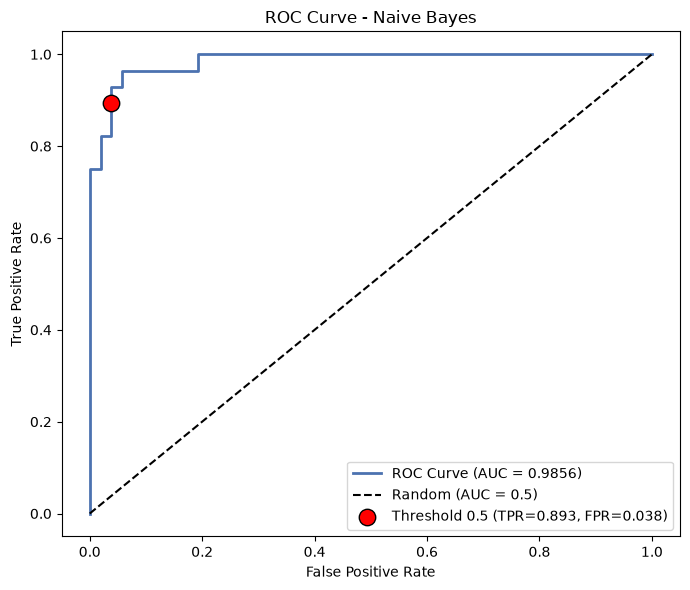

AUC = 0.9856


In [256]:
# ============================================================
# FUNGSI : Menghitung probabilitas posterior kelas Membeli & menggambar ROC Curve + AUC.
# HASIL  : AUC = 0.9856 -> model sangat baik dalam membedakan kelas.
#          Titik merah menandai performa model pada threshold 0.5.
# ============================================================
def prob_kelas1(baris):
    post = hitung_posterior(baris)
    total = post[0] + post[1]
    return post[1] / total if total > 0 else 0

proba = X_test.apply(prob_kelas1, axis=1).values

# Hitung ROC manual dengan menggeser threshold
thresholds = np.linspace(0, 1, 101)
TPR, FPR = [], []
for t in thresholds:
    pred = (proba >= t).astype(int)
    tp = ((y_test == 1) & (pred == 1)).sum()
    tn = ((y_test == 0) & (pred == 0)).sum()
    fp = ((y_test == 0) & (pred == 1)).sum()
    fn = ((y_test == 1) & (pred == 0)).sum()
    TPR.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
    FPR.append(fp / (fp + tn) if (fp + tn) > 0 else 0)

# AUC dengan metode trapesium
titik = sorted(zip(FPR, TPR))
xs = [p[0] for p in titik]
ys = [p[1] for p in titik]
auc = sum((xs[i + 1] - xs[i]) * (ys[i + 1] + ys[i]) / 2 for i in range(len(xs) - 1))

plt.figure(figsize=(7, 6))
plt.plot(FPR, TPR, color='#4C72B0', linewidth=2, label=f'ROC Curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')

# Titik operasi model pada threshold 0.5
pred_05 = (proba >= 0.5).astype(int)
tp_05 = ((y_test == 1) & (pred_05 == 1)).sum()
tn_05 = ((y_test == 0) & (pred_05 == 0)).sum()
fp_05 = ((y_test == 0) & (pred_05 == 1)).sum()
fn_05 = ((y_test == 1) & (pred_05 == 0)).sum()
tpr_05 = tp_05 / (tp_05 + fn_05)
fpr_05 = fp_05 / (fp_05 + tn_05)
plt.scatter([fpr_05], [tpr_05], color='red', s=140, zorder=5,
            edgecolors='black',
            label=f'Threshold 0.5 (TPR={tpr_05:.3f}, FPR={fpr_05:.3f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend()
plt.tight_layout()
plt.show()
print(f'AUC = {auc:.4f}')

# Kesimpulan

## 1. Kesimpulan Dataset
- Dataset **marketing.csv** memiliki **400 baris** dan **5 kolom**: `User ID`, `Gender`, `Age`, `EstimatedSalary`, dan `Purchased`.
- Kolom **Purchased** adalah target dengan distribusi **257 tidak membeli (64.25%)** dan **143 membeli (35.75%)**, sehingga termasuk **imbalance ringan**.
- Fitur kontinu: `Age` (18-60 tahun, rata-rata 37.66) dan `EstimatedSalary` (15.000-150.000, rata-rata 69.742).
- Fitur `Gender` relatif seimbang: **204 Female** dan **196 Male**.
- Dari hasil EDA, fitur `Age` dan `EstimatedSalary` memiliki korelasi paling kuat terhadap target (`Age` = 0.62, `EstimatedSalary` = 0.36), sedangkan `User ID` dan `Gender` hampir tidak berkorelasi.

## 2. Keputusan Data Preprocessing
- **Encoding `Gender`** menjadi numerik (Male=1, Female=0) agar bisa diproses model.
- **Menghapus kolom `User ID`** karena hanya identitas unik tanpa daya prediksi (korelasi ~0.01).
- **Cek outlier dengan IQR**: ditemukan **0 outlier**, sehingga tidak ada data yang dibuang.
- **Cek missing value & duplikat**: **0 null** dan **0 duplikat**, data sudah bersih.
- **Split data manual 80:20** (320 train / 80 test) menggunakan `seed=42` agar hasil konsisten.

## 3. Kesimpulan Algoritma
- Digunakan **Naive Bayes Gaussian tanpa sklearn**, karena fitur bersifat kontinu sehingga likelihood dimodelkan dengan **distribusi Gaussian**.
- Tahapan perhitungan berurutan: **Prior -> Likelihood -> Posterior**.
  - **Prior**: `P(Tidak Membeli) = 0.6406`, `P(Membeli) = 0.3594`.
  - **Likelihood**: kelas membeli punya `Age` (mean 45.83) dan `EstimatedSalary` (mean 87.722) yang jauh lebih tinggi dibanding kelas tidak membeli (`Age` 33.4, `Salary` 60.498) -> kedua fitur mampu memisahkan kelas dengan baik.
  - **Posterior**: prior dikali seluruh likelihood fitur, lalu kelas dengan nilai posterior terbesar dipilih sebagai prediksi.
- Naive Bayes mengasumsikan **independensi antar fitur**; korelasi `Age`-`EstimatedSalary` (0.155) tergolong rendah sehingga asumsi ini cukup wajar.
- **Kurva likelihood dan decision boundary** mengonfirmasi bahwa pemisahan kelas didominasi oleh `Age` dan `EstimatedSalary`, sedangkan `Gender` nyaris tidak menggeser batas keputusan.

## 4. Analisis Hasil Evaluasi
- **Confusion Matrix**: TP = 25, TN = 50, FP = 2, FN = 3.
- **Accuracy = 93.75%** -> model benar pada 75 dari 80 data test.
- **Precision = 92.59%** -> dari semua yang diprediksi membeli, 92.59% benar-benar membeli.
- **Recall = 89.29%** -> dari seluruh pembeli asli, 89.29% berhasil ditangkap model.
- **F1-Score = 90.91%** -> keseimbangan Precision dan Recall yang sangat baik.
- **AUC = 0.9856** -> model sangat baik membedakan kelas Membeli vs Tidak Membeli (jauh di atas 0.5).
- **Confusion matrix ternormalisasi**: 96.15% data "Tidak Membeli" dan 89.29% data "Membeli" diprediksi dengan benar.
- Karena **Recall < Precision**, model sedikit lebih sering *melewatkan* pembeli asli (3 false negative) dibanding salah menandai bukan pembeli (2 false positive).
- **Pengaruh fitur**: `Age` dan `EstimatedSalary` sangat menentukan prediksi (pergeseran peluang hingga ~0.94 dan ~0.79), sedangkan `Gender` hampir tidak berpengaruh (selisih peluang hanya 0.019).
- Secara keseluruhan model **sangat baik** (hanya 5 kesalahan dari 80 data), dengan `Age` sebagai fitur paling dominan.

## 5. Prediksi & Rekomendasi
- Model dapat memprediksi kecenderungan pembelian: pelanggan dengan **usia dan gaji lebih tinggi** cenderung **membeli**.
- **Rekomendasi bisnis**: fokuskan kampanye pemasaran pada segmen pelanggan usia lebih tua dan berpendapatan lebih tinggi untuk hasil yang lebih efektif.
- **Pengembangan lanjutan**: gunakan *k-fold cross validation*, *hyperparameter tuning*, penambahan fitur relevan, serta membandingkan dengan algoritma lain (KNN, Decision Tree, Logistic Regression) untuk validasi performa.
